In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import transforms
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import ImageFolder
from torchvision import datasets
import os, time, copy
import matplotlib.pyplot as plt
from torchvision import models
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = 3

In [3]:
transform = transforms.Compose([
    transforms.Resize((64,64),antialias = True),
    transforms.ToTensor()
])

from pathlib import Path
from torch.utils.data import Subset

import kagglehub
root = Path(kagglehub.dataset_download("drgfreeman/rockpaperscissors"))
print(root)

class RockPaperScissors(datasets.ImageFolder):
    def find_classes(self, directory):
        classes = ["paper", "rock", "scissors"]

        for name in classes:
            if not (Path(directory) / name).is_dir():
                raise FileNotFoundError(f"Missing class folder: {name}")

        return classes, {name: i for i, name in enumerate(classes)}

dataset = RockPaperScissors(root=root, transform=transform)

print(dataset.class_to_idx)
print("Total images:", len(dataset))
print("Per class:", np.bincount(dataset.targets))

Using Colab cache for faster access to the 'rockpaperscissors' dataset.
/kaggle/input/rockpaperscissors
{'paper': 0, 'rock': 1, 'scissors': 2}
Total images: 2188
Per class: [712 726 750]


In [4]:
total= len(dataset)

train_size = int(0.7*total)
val_size = int(0.15*total)
test_size = total - train_size - val_size

trainset, valset, testset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator  = torch.Generator().manual_seed(42)
)

In [5]:
batch_size = 64

training_data = DataLoader(trainset, batch_size=batch_size, shuffle=True)
val_data = DataLoader(valset, batch_size=batch_size, shuffle=False)
testing_data = DataLoader(testset, batch_size=batch_size, shuffle=False)

norm_transform = transforms.Compose([
    transforms.Resize((64, 64), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
dataset_norm = RockPaperScissors(root=root, transform=norm_transform)
training_data_norm = DataLoader(Subset(dataset_norm, trainset.indices), batch_size=64, shuffle=True)
val_data_norm = DataLoader(Subset(dataset_norm, valset.indices), batch_size=64, shuffle=False)
testing_data_norm = DataLoader(Subset(dataset_norm, testset.indices), batch_size=64, shuffle=False)

**CNN 1**

In [6]:
class CNN1(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels = 3, out_channels = 6, kernel_size = 5)
        self.pool1 = nn.MaxPool2d(2,2)
        self.conv2 = nn.Conv2d(6,5,5)
        self.fc1 = nn.Linear(5*13*13, 117)
        self.fc2 = nn.Linear(117,3)

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool1(F.relu(self.conv2(x)))
        x = torch.flatten(x,1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [7]:
def train_model(model, optimizer, train_loader, val_loader, epochs=20):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "epoch_time": []}
    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        model.train()
        start = time.perf_counter()
        running_loss, total_images = 0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
            total_images += inputs.size(0)
        history["epoch_time"].append(time.perf_counter() - start)
        history["train_loss"].append(running_loss / total_images)

        model.eval()
        running_val_loss, total_val_images = 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                running_val_loss += criterion(model(inputs), labels).item() * inputs.size(0)
                total_val_images += inputs.size(0)
        epoch_val_loss = running_val_loss / total_val_images
        history["val_loss"].append(epoch_val_loss)

        if epoch_val_loss < best_val_loss:                 # keep the best epoch
            best_val_loss = epoch_val_loss
            best_weights = copy.deepcopy(model.state_dict())

        print(f"Epoch {epoch + 1}/{epochs} | Training loss: {history['train_loss'][-1]:.4f} | "
              f"Validation loss: {epoch_val_loss:.4f} | Time: {history['epoch_time'][-1]:.2f} s")

    print(f"Finished Training | best val loss: {best_val_loss:.4f} | "
          f"avg time/epoch (epochs 2-{epochs}): {np.mean(history['epoch_time'][1:]):.2f} s")
    model.load_state_dict(best_weights)
    return model, history


def count_macs(model, input_size=(1, 3, 64, 64)):
    """Multiply-accumulate operations for one image (Conv2d + Linear layers)."""
    macs = 0
    def conv_hook(m, inp, out):
        nonlocal macs
        macs += out.numel() * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
    def linear_hook(m, inp, out):
        nonlocal macs
        macs += out.numel() * m.in_features
    hooks = [m.register_forward_hook(conv_hook if isinstance(m, nn.Conv2d) else linear_hook)
             for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    model.eval()
    with torch.no_grad():
        model(torch.zeros(input_size, device=next(model.parameters()).device))
    for h in hooks:
        h.remove()
    return macs


def evaluate_model(model, test_loader, filename):
    model.eval()
    true_labels, predictions = [], []
    with torch.no_grad():
        for images, labels in test_loader:                 # was: testing_data
            outputs = model(images.to(device))
            predictions.extend(outputs.argmax(dim=1).cpu().tolist())
            true_labels.extend(labels.tolist())

    accuracy = accuracy_score(true_labels, predictions)
    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels, predictions, labels=list(range(num_classes)),
        average="macro", zero_division=0)
    cm = confusion_matrix(true_labels, predictions, labels=list(range(num_classes)))
    total_params = sum(p.numel() for p in model.parameters())

    # Save only weights and buffers (no optimizer state) to measure the size on disk
    torch.save({name: t.detach().cpu() for name, t in model.state_dict().items()}, filename)
    size_kb = os.path.getsize(filename) / 1000

    print(f"\n{filename}")
    print(f"Accuracy:         {100 * accuracy:.2f}%")
    print(f"Macro precision:  {100 * precision:.2f}%")
    print(f"Macro recall:     {100 * recall:.2f}%")
    print(f"Macro F1:         {100 * f1:.2f}%")
    print(f"Total parameters: {total_params:,}")
    print(f"Model size:       {size_kb:.1f} KB ({size_kb / 1000:.2f} MB)")
    print(f"MACs per image:   {count_macs(model) / 1e6:.3f} M")
    print("Confusion matrix:\n", cm)
    return {"accuracy": accuracy, "cm": cm}


def plot_cms(items, filename):
    fig, axes = plt.subplots(1, len(items), figsize=(4.2 * len(items), 3.8))
    for ax, (title, res) in zip(axes, items):
        ConfusionMatrixDisplay(res["cm"], display_labels=["paper", "rock", "scissors"]).plot(
            ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(title)
    plt.tight_layout(); plt.savefig(filename, dpi=200); plt.show()

In [8]:
torch.manual_seed(0)
CNN = CNN1()
optimizer = optim.Adam(CNN.parameters(), lr=0.001)
CNN, hist_A_adam = train_model(CNN, optimizer, training_data, val_data)
res_A_adam = evaluate_model(CNN, testing_data, "modelA_adam.pth")

Epoch 1/20 | Training loss: 1.0368 | Validation loss: 0.8498 | Time: 14.40 s
Epoch 2/20 | Training loss: 0.6630 | Validation loss: 0.5435 | Time: 4.51 s
Epoch 3/20 | Training loss: 0.5112 | Validation loss: 0.4862 | Time: 4.49 s
Epoch 4/20 | Training loss: 0.4111 | Validation loss: 0.4354 | Time: 4.93 s
Epoch 5/20 | Training loss: 0.3392 | Validation loss: 0.3708 | Time: 4.88 s
Epoch 6/20 | Training loss: 0.2680 | Validation loss: 0.3502 | Time: 4.50 s
Epoch 7/20 | Training loss: 0.2243 | Validation loss: 0.2642 | Time: 4.44 s
Epoch 8/20 | Training loss: 0.2145 | Validation loss: 0.2651 | Time: 4.95 s
Epoch 9/20 | Training loss: 0.1644 | Validation loss: 0.2585 | Time: 4.46 s
Epoch 10/20 | Training loss: 0.1508 | Validation loss: 0.2592 | Time: 4.48 s
Epoch 11/20 | Training loss: 0.1195 | Validation loss: 0.1663 | Time: 4.97 s
Epoch 12/20 | Training loss: 0.0900 | Validation loss: 0.1701 | Time: 4.42 s
Epoch 13/20 | Training loss: 0.0854 | Validation loss: 0.1528 | Time: 4.46 s
Epoch 1

In [9]:
torch.manual_seed(0)
CNN = CNN1()
optimizer = optim.SGD(CNN.parameters(), lr=0.001)
CNN, hist_A_sgd = train_model(CNN, optimizer, training_data, val_data)
res_A_sgd = evaluate_model(CNN, testing_data, "modelA_sgd.pth")

Epoch 1/20 | Training loss: 1.0975 | Validation loss: 1.0980 | Time: 4.43 s
Epoch 2/20 | Training loss: 1.0974 | Validation loss: 1.0979 | Time: 4.44 s
Epoch 3/20 | Training loss: 1.0972 | Validation loss: 1.0978 | Time: 4.47 s
Epoch 4/20 | Training loss: 1.0971 | Validation loss: 1.0977 | Time: 4.46 s
Epoch 5/20 | Training loss: 1.0970 | Validation loss: 1.0976 | Time: 4.42 s
Epoch 6/20 | Training loss: 1.0969 | Validation loss: 1.0975 | Time: 4.37 s
Epoch 7/20 | Training loss: 1.0968 | Validation loss: 1.0975 | Time: 4.44 s
Epoch 8/20 | Training loss: 1.0968 | Validation loss: 1.0974 | Time: 4.40 s
Epoch 9/20 | Training loss: 1.0967 | Validation loss: 1.0974 | Time: 4.46 s
Epoch 10/20 | Training loss: 1.0966 | Validation loss: 1.0973 | Time: 4.46 s
Epoch 11/20 | Training loss: 1.0965 | Validation loss: 1.0973 | Time: 4.44 s
Epoch 12/20 | Training loss: 1.0964 | Validation loss: 1.0972 | Time: 4.40 s
Epoch 13/20 | Training loss: 1.0964 | Validation loss: 1.0972 | Time: 4.45 s
Epoch 14

In [10]:
torch.manual_seed(0)
CNN = CNN1()
optimizer = optim.SGD(CNN.parameters(), lr=0.001, momentum=0.9)
CNN, hist_A_mom = train_model(CNN, optimizer, training_data, val_data)
res_A_mom = evaluate_model(CNN, testing_data, "modelA_momentum.pth")

Epoch 1/20 | Training loss: 1.0973 | Validation loss: 1.0976 | Time: 4.41 s
Epoch 2/20 | Training loss: 1.0965 | Validation loss: 1.0970 | Time: 4.44 s
Epoch 3/20 | Training loss: 1.0957 | Validation loss: 1.0964 | Time: 4.37 s
Epoch 4/20 | Training loss: 1.0949 | Validation loss: 1.0957 | Time: 4.46 s
Epoch 5/20 | Training loss: 1.0940 | Validation loss: 1.0948 | Time: 4.41 s
Epoch 6/20 | Training loss: 1.0928 | Validation loss: 1.0935 | Time: 4.46 s
Epoch 7/20 | Training loss: 1.0911 | Validation loss: 1.0919 | Time: 4.49 s
Epoch 8/20 | Training loss: 1.0887 | Validation loss: 1.0890 | Time: 4.43 s
Epoch 9/20 | Training loss: 1.0853 | Validation loss: 1.0847 | Time: 4.40 s
Epoch 10/20 | Training loss: 1.0799 | Validation loss: 1.0780 | Time: 4.42 s
Epoch 11/20 | Training loss: 1.0713 | Validation loss: 1.0676 | Time: 4.41 s
Epoch 12/20 | Training loss: 1.0563 | Validation loss: 1.0467 | Time: 4.45 s
Epoch 13/20 | Training loss: 1.0275 | Validation loss: 1.0059 | Time: 4.44 s
Epoch 14

**CNN 2**

In [11]:
class CNN2(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels = 3, out_channels = 3, kernel_size = 5, groups =3, bias = False),
            nn.Conv2d(in_channels = 3, out_channels = 6, kernel_size = 1)
        )
        self.pool1 = nn.MaxPool2d(2,2)
        self.conv2 = nn.Sequential(
            nn.Conv2d(in_channels = 6, out_channels = 6, kernel_size =5,  groups = 6, bias = False),
            nn.Conv2d(in_channels = 6, out_channels = 16, kernel_size = 1)
        )
        self.fc1 = nn.Linear(16*13*13, 36)
        self.fc2 = nn.Linear(36 , 3)

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool1(F.relu(self.conv2(x)))
        x = torch.flatten(x,1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

In [12]:
torch.manual_seed(0)
model_b = CNN2()
optimizer = optim.Adam(model_b.parameters(), lr=0.001)
model_b, hist_B_adam = train_model(model_b, optimizer, training_data, val_data)
res_B_adam = evaluate_model(model_b, testing_data, "modelB_adam.pth")

Epoch 1/20 | Training loss: 1.1036 | Validation loss: 1.0981 | Time: 4.55 s
Epoch 2/20 | Training loss: 1.0998 | Validation loss: 1.1015 | Time: 4.33 s
Epoch 3/20 | Training loss: 1.0946 | Validation loss: 1.0864 | Time: 4.43 s
Epoch 4/20 | Training loss: 1.0364 | Validation loss: 0.9414 | Time: 4.38 s
Epoch 5/20 | Training loss: 0.7894 | Validation loss: 0.6532 | Time: 4.39 s
Epoch 6/20 | Training loss: 0.5669 | Validation loss: 0.4968 | Time: 4.39 s
Epoch 7/20 | Training loss: 0.4624 | Validation loss: 0.4563 | Time: 4.41 s
Epoch 8/20 | Training loss: 0.4216 | Validation loss: 0.4546 | Time: 4.35 s
Epoch 9/20 | Training loss: 0.3739 | Validation loss: 0.4038 | Time: 4.38 s
Epoch 10/20 | Training loss: 0.3363 | Validation loss: 0.3692 | Time: 4.39 s
Epoch 11/20 | Training loss: 0.3011 | Validation loss: 0.3591 | Time: 4.41 s
Epoch 12/20 | Training loss: 0.2732 | Validation loss: 0.3203 | Time: 4.46 s
Epoch 13/20 | Training loss: 0.2430 | Validation loss: 0.2940 | Time: 4.35 s
Epoch 14

In [13]:
torch.manual_seed(0)
model_b = CNN2()
optimizer = optim.SGD(model_b.parameters(), lr=0.001)
model_b, hist_B_sgd = train_model(model_b, optimizer, training_data, val_data)
res_B_sgd = evaluate_model(model_b, testing_data, "modelB_sgd.pth")

Epoch 1/20 | Training loss: 1.0995 | Validation loss: 1.0992 | Time: 4.42 s
Epoch 2/20 | Training loss: 1.0992 | Validation loss: 1.0990 | Time: 4.40 s
Epoch 3/20 | Training loss: 1.0990 | Validation loss: 1.0989 | Time: 4.37 s
Epoch 4/20 | Training loss: 1.0988 | Validation loss: 1.0988 | Time: 4.40 s
Epoch 5/20 | Training loss: 1.0987 | Validation loss: 1.0987 | Time: 4.41 s
Epoch 6/20 | Training loss: 1.0986 | Validation loss: 1.0986 | Time: 4.39 s
Epoch 7/20 | Training loss: 1.0984 | Validation loss: 1.0986 | Time: 4.44 s
Epoch 8/20 | Training loss: 1.0983 | Validation loss: 1.0985 | Time: 4.39 s
Epoch 9/20 | Training loss: 1.0982 | Validation loss: 1.0985 | Time: 4.40 s
Epoch 10/20 | Training loss: 1.0982 | Validation loss: 1.0985 | Time: 4.36 s
Epoch 11/20 | Training loss: 1.0981 | Validation loss: 1.0984 | Time: 4.40 s
Epoch 12/20 | Training loss: 1.0980 | Validation loss: 1.0984 | Time: 4.41 s
Epoch 13/20 | Training loss: 1.0979 | Validation loss: 1.0984 | Time: 4.39 s
Epoch 14

In [14]:
torch.manual_seed(0)
model_b = CNN2()
optimizer = optim.SGD(model_b.parameters(), lr=0.001, momentum=0.9)
model_b, hist_B_mom = train_model(model_b, optimizer, training_data, val_data)
res_B_mom = evaluate_model(model_b, testing_data, "modelB_momentum.pth")

Epoch 1/20 | Training loss: 1.0994 | Validation loss: 1.0985 | Time: 4.38 s
Epoch 2/20 | Training loss: 1.0983 | Validation loss: 1.0982 | Time: 4.44 s
Epoch 3/20 | Training loss: 1.0978 | Validation loss: 1.0986 | Time: 4.40 s
Epoch 4/20 | Training loss: 1.0979 | Validation loss: 1.0989 | Time: 4.43 s
Epoch 5/20 | Training loss: 1.0983 | Validation loss: 1.0981 | Time: 4.38 s
Epoch 6/20 | Training loss: 1.0979 | Validation loss: 1.0989 | Time: 4.41 s
Epoch 7/20 | Training loss: 1.0980 | Validation loss: 1.0987 | Time: 4.35 s
Epoch 8/20 | Training loss: 1.0977 | Validation loss: 1.0986 | Time: 4.42 s
Epoch 9/20 | Training loss: 1.0977 | Validation loss: 1.0987 | Time: 4.52 s
Epoch 10/20 | Training loss: 1.0977 | Validation loss: 1.0987 | Time: 4.65 s
Epoch 11/20 | Training loss: 1.0979 | Validation loss: 1.0986 | Time: 4.46 s
Epoch 12/20 | Training loss: 1.0978 | Validation loss: 1.0988 | Time: 4.45 s
Epoch 13/20 | Training loss: 1.0977 | Validation loss: 1.0984 | Time: 4.44 s
Epoch 14

Optimizer comparison
Model A | Adam           final train loss 0.0622 | best val loss 0.1082 | test acc 97.26%
Model A | SGD            final train loss 1.0958 | best val loss 1.0967 | test acc 31.91%
Model A | SGD+Momentum   final train loss 0.4685 | best val loss 0.4692 | test acc 86.63%
Model B | Adam           final train loss 0.1324 | best val loss 0.2364 | test acc 94.22%
Model B | SGD            final train loss 1.0977 | best val loss 1.0984 | test acc 31.91%
Model B | SGD+Momentum   final train loss 1.0979 | best val loss 1.0980 | test acc 31.91%


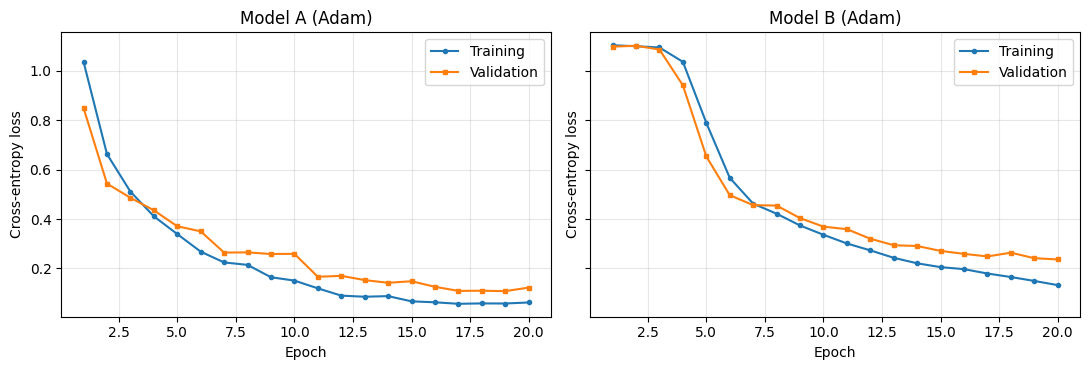

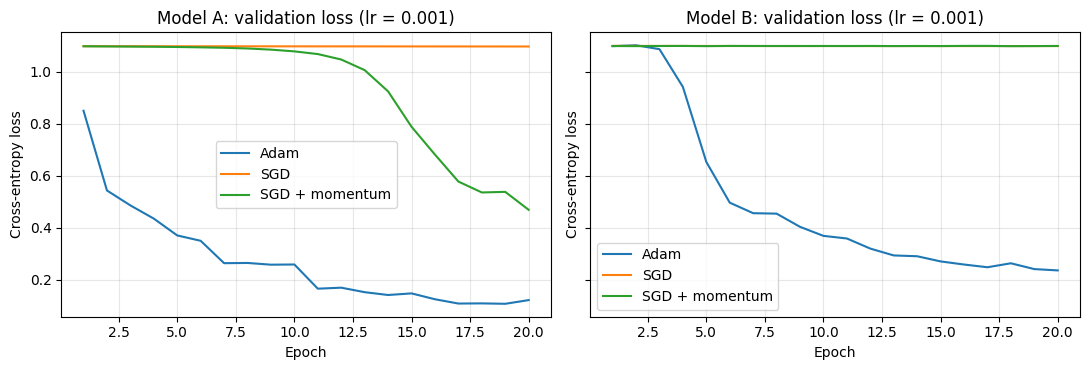

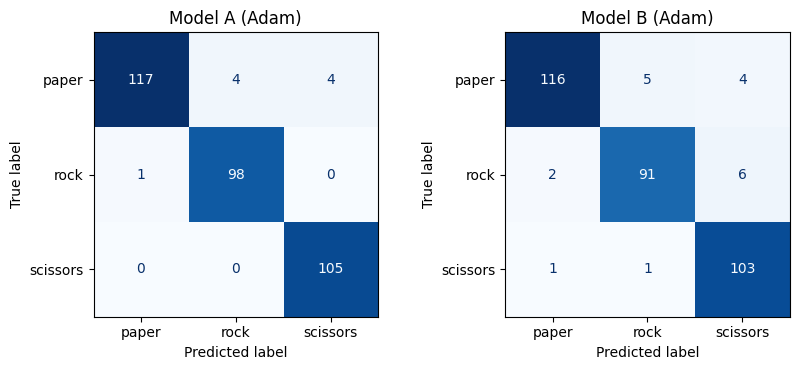

In [15]:
print("Optimizer comparison")
for name, hist, res in [("Model A | Adam", hist_A_adam, res_A_adam),
                        ("Model A | SGD", hist_A_sgd, res_A_sgd),
                        ("Model A | SGD+Momentum", hist_A_mom, res_A_mom),
                        ("Model B | Adam", hist_B_adam, res_B_adam),
                        ("Model B | SGD", hist_B_sgd, res_B_sgd),
                        ("Model B | SGD+Momentum", hist_B_mom, res_B_mom)]:
    print(f"{name:24s} final train loss {hist['train_loss'][-1]:.4f} | "
          f"best val loss {min(hist['val_loss']):.4f} | test acc {100 * res['accuracy']:.2f}%")

epochs = range(1, 21)

# Training / validation loss curves (Adam)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, title, hist in [(axes[0], "Model A (Adam)", hist_A_adam),
                        (axes[1], "Model B (Adam)", hist_B_adam)]:
    ax.plot(epochs, hist["train_loss"], "o-", ms=3, label="Training")
    ax.plot(epochs, hist["val_loss"], "s-", ms=3, label="Validation")
    ax.set(title=title, xlabel="Epoch", ylabel="Cross-entropy loss")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig("loss-curves.png", dpi=200); plt.show()

# Validation loss for the three optimizers
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, title, hists in [(axes[0], "Model A", [hist_A_adam, hist_A_sgd, hist_A_mom]),
                         (axes[1], "Model B", [hist_B_adam, hist_B_sgd, hist_B_mom])]:
    for hist, label in zip(hists, ["Adam", "SGD", "SGD + momentum"]):
        ax.plot(epochs, hist["val_loss"], label=label)
    ax.set(title=f"{title}: validation loss (lr = 0.001)", xlabel="Epoch", ylabel="Cross-entropy loss")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig("optimizer-comparison.png", dpi=200); plt.show()

plot_cms([("Model A (Adam)", res_A_adam), ("Model B (Adam)", res_B_adam)], "confusion-custom.png")

# **Pre Trained Model**

In [16]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = 3

# Model 1: MobileNetV2
mobilenet = models.mobilenet_v2(
    weights=models.MobileNet_V2_Weights.DEFAULT
)

mobilenet.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features,
    num_classes
)

# Model 2: ShuffleNetV2
shufflenet = models.shufflenet_v2_x0_5(
    weights=models.ShuffleNet_V2_X0_5_Weights.DEFAULT
)

shufflenet.fc = nn.Linear(
    shufflenet.fc.in_features,
    num_classes
)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 66.7MB/s]


Downloading: "https://download.pytorch.org/models/shufflenetv2_x0.5-f707e7126e.pth" to /root/.cache/torch/hub/checkpoints/shufflenetv2_x0.5-f707e7126e.pth


100%|██████████| 5.28M/5.28M [00:00<00:00, 77.1MB/s]


In [17]:
torch.manual_seed(0)
mobilenet, hist_mobilenet = train_model(
    mobilenet, optim.Adam(mobilenet.parameters(), lr=1e-4),
    training_data_norm, val_data_norm, epochs=15)

torch.manual_seed(0)
shufflenet, hist_shufflenet = train_model(
    shufflenet, optim.Adam(shufflenet.parameters(), lr=1e-4),
    training_data_norm, val_data_norm, epochs=15)

Epoch 1/15 | Training loss: 0.9375 | Validation loss: 0.6152 | Time: 5.96 s
Epoch 2/15 | Training loss: 0.5327 | Validation loss: 0.3680 | Time: 5.70 s
Epoch 3/15 | Training loss: 0.2854 | Validation loss: 0.2187 | Time: 5.69 s
Epoch 4/15 | Training loss: 0.1551 | Validation loss: 0.1355 | Time: 5.63 s
Epoch 5/15 | Training loss: 0.0854 | Validation loss: 0.0950 | Time: 5.73 s
Epoch 6/15 | Training loss: 0.0604 | Validation loss: 0.0745 | Time: 5.68 s
Epoch 7/15 | Training loss: 0.0378 | Validation loss: 0.0603 | Time: 5.66 s
Epoch 8/15 | Training loss: 0.0312 | Validation loss: 0.0478 | Time: 5.71 s
Epoch 9/15 | Training loss: 0.0180 | Validation loss: 0.0427 | Time: 5.70 s
Epoch 10/15 | Training loss: 0.0189 | Validation loss: 0.0389 | Time: 5.68 s
Epoch 11/15 | Training loss: 0.0134 | Validation loss: 0.0336 | Time: 5.71 s
Epoch 12/15 | Training loss: 0.0112 | Validation loss: 0.0304 | Time: 5.65 s
Epoch 13/15 | Training loss: 0.0105 | Validation loss: 0.0295 | Time: 5.66 s
Epoch 14


mobilenet_v2.pth
Accuracy:         100.00%
Macro precision:  100.00%
Macro recall:     100.00%
Macro F1:         100.00%
Total parameters: 2,227,715
Model size:       9143.9 KB (9.14 MB)
MACs per image:   24.452 M
Confusion matrix:
 [[125   0   0]
 [  0  99   0]
 [  0   0 105]]

shufflenet_v2.pth
Accuracy:         100.00%
Macro precision:  100.00%
Macro recall:     100.00%
Macro F1:         100.00%
Total parameters: 344,867
Model size:       1513.1 KB (1.51 MB)
MACs per image:   3.224 M
Confusion matrix:
 [[125   0   0]
 [  0  99   0]
 [  0   0 105]]


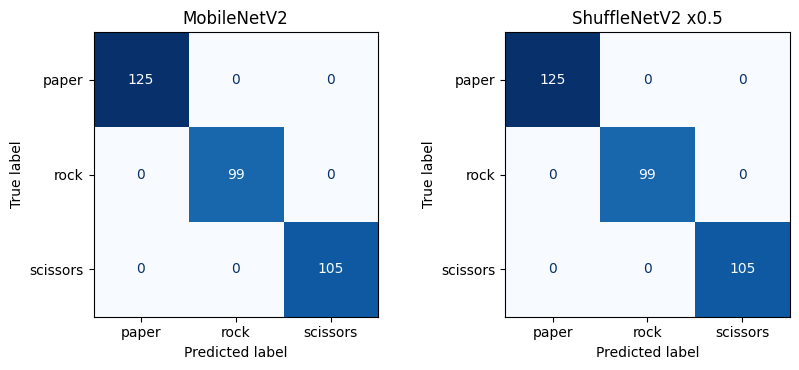

In [18]:
res_mobilenet = evaluate_model(mobilenet, testing_data_norm, "mobilenet_v2.pth")
res_shufflenet = evaluate_model(shufflenet, testing_data_norm, "shufflenet_v2.pth")
plot_cms([("MobileNetV2", res_mobilenet), ("ShuffleNetV2 x0.5", res_shufflenet)], "confusion-sota.png")